Netflix Data Analysis

Objective
To analyze Netflix dataset and extract insights about content distribution, growth trends, and genre popularity.

Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\user\Documents\DS Projects\Netflix_Project\netflix_titles.csv.zip")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
# Clean date column safely
df['date_added'] = df['date_added'].astype(str).str.strip()
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

# Drop rows with invalid dates
df = df.dropna(subset=['date_added'])

# Fill missing values
df.fillna({
    'director': 'Unknown',
    'cast': 'Unknown',
    'country': 'Unknown',
    'rating': 'Not Rated'
}, inplace=True)

In [6]:
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

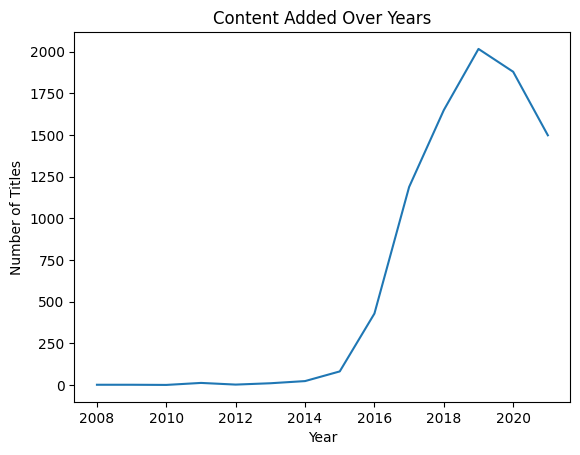

In [7]:
year_counts = df['year_added'].value_counts().sort_index()

year_counts.plot()
plt.title("Content Added Over Years")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.show()

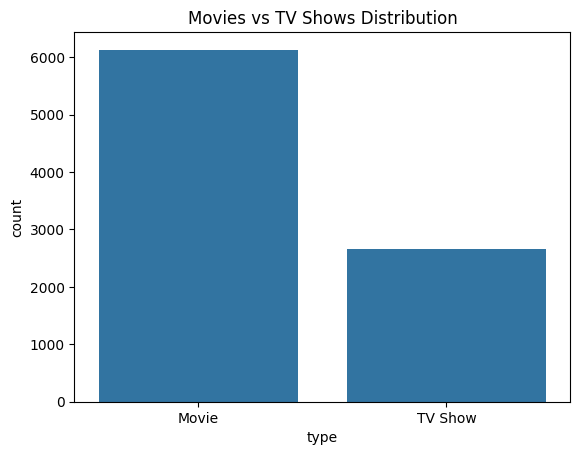

In [8]:
sns.countplot(x='type', data=df)
plt.title("Movies vs TV Shows Distribution")
plt.show()

- The United States is the leading contributor to Netflix content, reflecting its dominance in the entertainment industry.
- India is also among the top contributors, highlighting Netflix’s expansion into emerging markets.
- The distribution shows that Netflix sources content globally, supporting its international audience base.

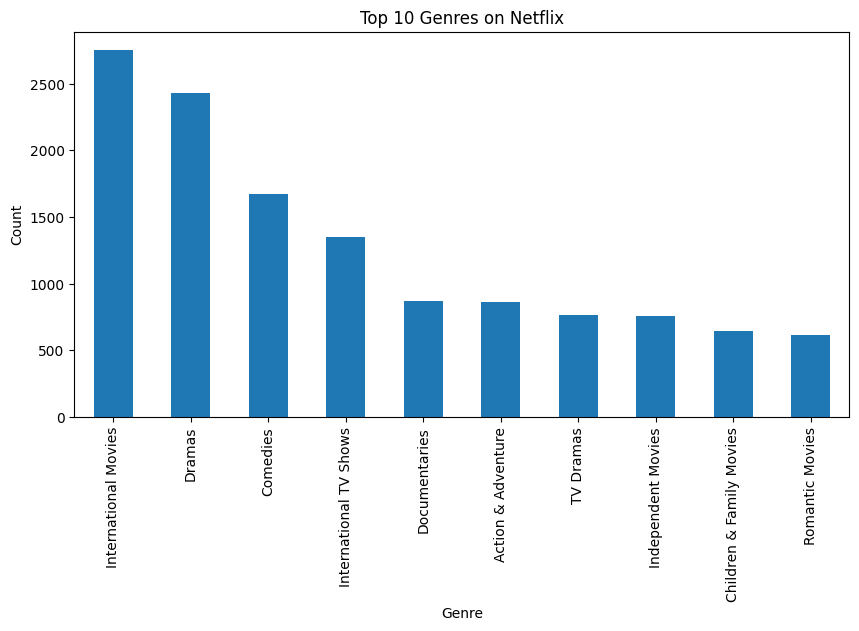

In [10]:
genres = df['listed_in'].str.split(', ', expand=True).stack()

top_genres = genres.value_counts().head(10)

top_genres.plot(kind='bar', figsize=(10,5))
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.show()

- Drama is the most dominant genre, indicating strong audience preference for storytelling-driven content.
- Comedy is also highly prevalent, suggesting demand for light and entertaining content.
- Documentaries and international genres show that Netflix caters to diverse viewer interests.

<Axes: >

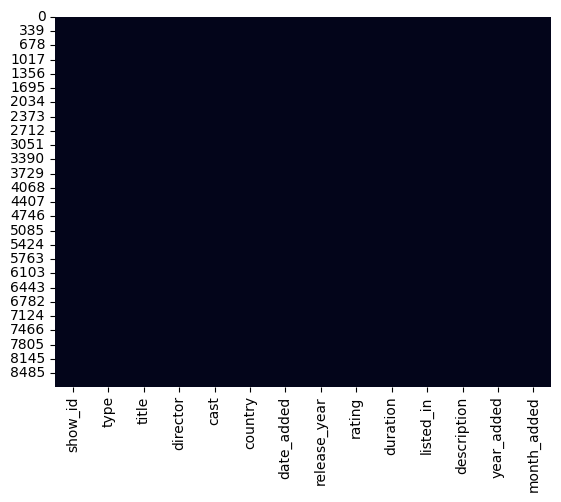

In [11]:
sns.heatmap(df.isnull(), cbar=False)

- Netflix content has grown significantly after 2015, reflecting rapid platform expansion.
- Movies dominate the platform, indicating a strong focus on film-based content.
- The United States is the primary content producer, followed by emerging markets like India.
- Drama and Comedy are the most popular genres, showing audience preference trends.
- Netflix maintains a diverse content strategy by including multiple genres and international productions.